Mounted at /content/drive
📂 Loading test data...
⚙️ Preparing the 11 features used during training...
⚙️ X_rf_test.npy not found. Reconstructing features dynamically...
✅ Final shape for prediction: (141123, 11) (Expected: N, 11)

🧠 Loading XGBoost from lightgbm_baseline.pkl...


/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:35:47] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


⚡ Predicting with XGBoost...

🧠 Loading LightGBM from actuallightgbm_baseline.pkl...
⚡ Predicting with LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

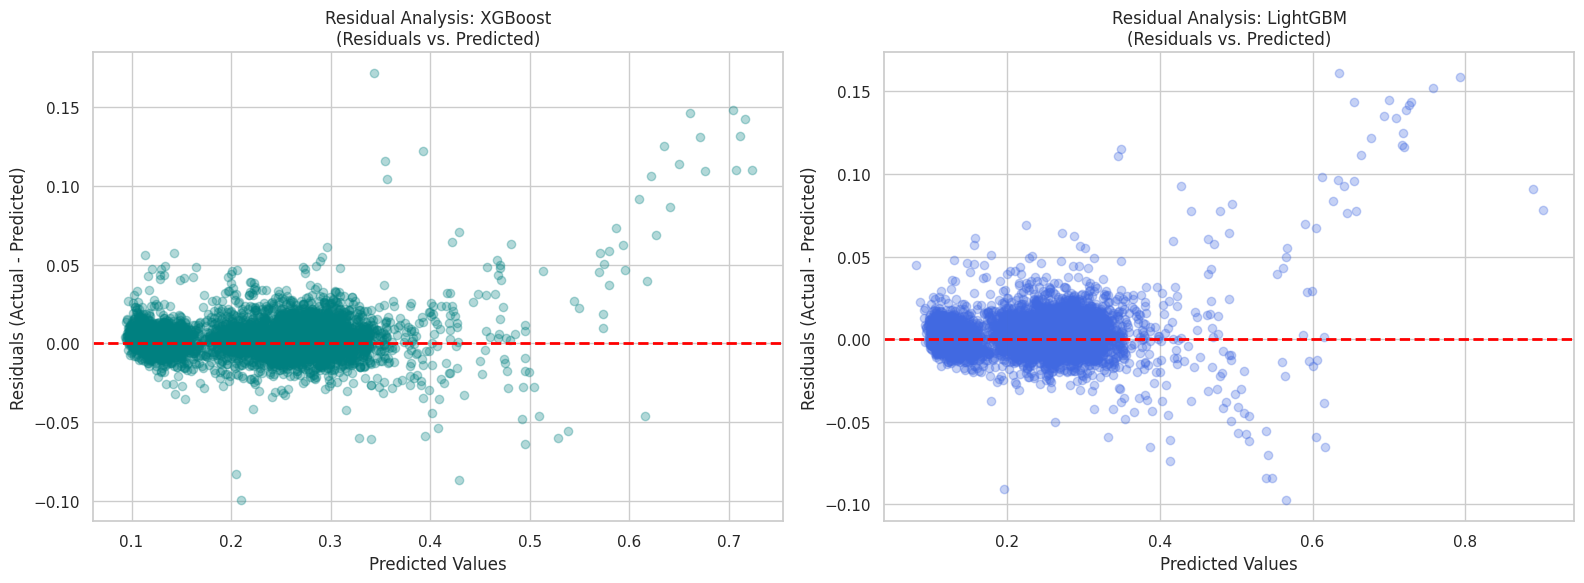


✅ Residual Analysis plots generated successfully!


In [2]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Paths Configuration
DATA_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'
MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'

# 3. Load Test Data
print("📂 Loading test data...")
X_seq_test = np.load(os.path.join(DATA_DIR, 'X_seq_test.npy'))
X_phys_test = np.load(os.path.join(DATA_DIR, 'X_phys_test.npy'))
y_test = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

# 4. Feature Engineering for Tree Models (The 11-Feature Fix)
print("⚙️ Preparing the 11 features used during training...")
rf_test_path = os.path.join(DATA_DIR, 'X_rf_test.npy')

# If you saved X_rf_test, we load it. Otherwise, we reconstruct it!
if os.path.exists(rf_test_path):
    print("📂 Found X_rf_test.npy! Loading directly...")
    X_tree_test = np.load(rf_test_path)
else:
    print("⚙️ X_rf_test.npy not found. Reconstructing features dynamically...")
    # Grab ONLY the last time step from the sequence (index -1)
    # X_seq_test is (samples, 48, 9) -> X_last_step becomes (samples, 9)
    X_last_step = X_seq_test[:, -1, :]

    # Combine the 9 sequence features with the 2 physical features (9 + 2 = 11)
    X_tree_test = np.hstack([X_last_step, X_phys_test])

print(f"✅ Final shape for prediction: {X_tree_test.shape} (Expected: N, 11)")

# 5. Load Models and Generate Predictions
models_to_plot = {
    "XGBoost": "lightgbm_baseline.pkl",
    "LightGBM": "actuallightgbm_baseline.pkl"
}

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

for i, (model_name, file_name) in enumerate(models_to_plot.items(), 1):
    path = os.path.join(MODEL_DIR, file_name)

    if os.path.exists(path):
        print(f"\n🧠 Loading {model_name} from {file_name}...")

        # Note: You can ignore the XGBoost pickle UserWarning printed in the console
        model = joblib.load(path)

        print(f"⚡ Predicting with {model_name}...")
        y_pred = model.predict(X_tree_test)

        # Flatten for analysis
        y_true_f = y_test.flatten()
        y_pred_f = y_pred.flatten()

        # Ensure alignment (just in case shapes differ slightly)
        min_len = min(len(y_true_f), len(y_pred_f))
        y_true_f = y_true_f[:min_len]
        y_pred_f = y_pred_f[:min_len]

        residuals = y_true_f - y_pred_f

        # --- PLOTTING ---
        plt.subplot(1, 2, i)

        # Sampling 5000 points to keep Colab from freezing
        sample_size = min(5000, len(y_pred_f))
        idx = np.random.choice(len(y_pred_f), sample_size, replace=False)

        plt.scatter(y_pred_f[idx], residuals[idx], alpha=0.3, color='teal' if i==1 else 'royalblue')
        plt.axhline(y=0, color='red', linestyle='--', linewidth=2)

        plt.title(f"Residual Analysis: {model_name}\n(Residuals vs. Predicted)")
        plt.xlabel("Predicted Values")
        plt.ylabel("Residuals (Actual - Predicted)")
    else:
        print(f"⚠️ Warning: Model file {file_name} not found in {MODEL_DIR}")

plt.tight_layout()
plt.show()

print("\n✅ Residual Analysis plots generated successfully!")

In [3]:
import os
import joblib
import numpy as np

print("📊 Mean Predictions across test samples:\n" + "-"*40)

# Calculate Actual Mean for comparison
mean_actual = np.mean(y_test)
print(f"🎯 Actual Mean (y_test): {mean_actual:.4f}\n")

# Calculate Mean Predictions for each model
for model_name, file_name in models_to_plot.items():
    path = os.path.join(MODEL_DIR, file_name)

    if os.path.exists(path):
        model = joblib.load(path)
        y_pred = model.predict(X_tree_test)

        mean_pred = np.mean(y_pred)
        print(f"👉 {model_name} Mean Prediction: {mean_pred:.4f}")
    else:
        print(f"⚠️ Model {model_name} not found.")

📊 Mean Predictions across test samples:
----------------------------------------
🎯 Actual Mean (y_test): 0.2323

👉 XGBoost Mean Prediction: 0.2289


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

👉 LightGBM Mean Prediction: 0.2293


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

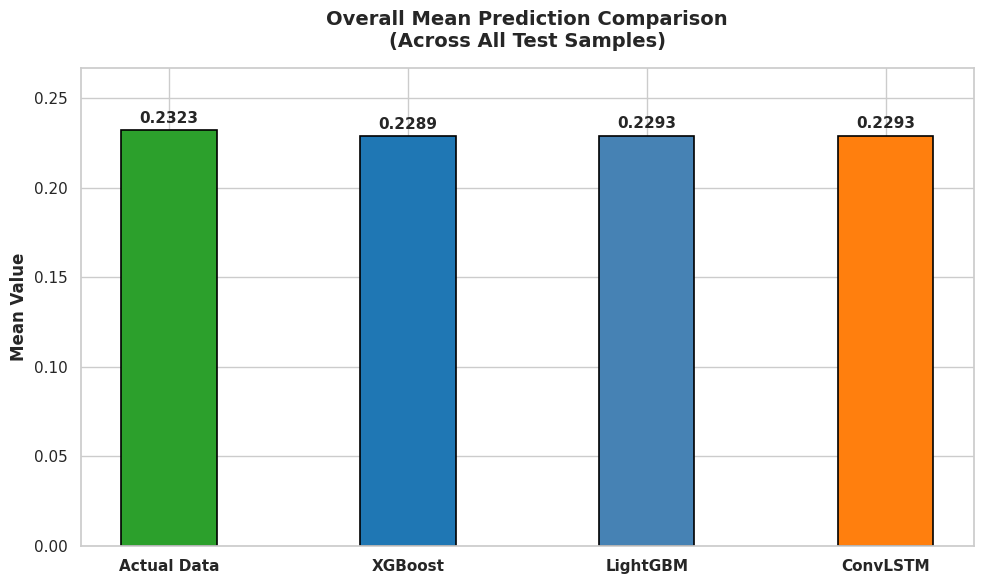

In [4]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Collect names and calculate means
model_names = ['Actual Data']
mean_values = [np.mean(y_test)]

# Loop through tree models to get their means
for model_name, file_name in models_to_plot.items():
    path = os.path.join(MODEL_DIR, file_name)
    if os.path.exists(path):
        model = joblib.load(path)
        y_pred = model.predict(X_tree_test)

        mean_values.append(np.mean(y_pred))
        model_names.append(model_name)

# 💡 ConvLSTM check: Agar pichle cell ki variable 'y_pred_f' memory mein hai, toh usey bhi add kar lo
if 'y_pred_f' in globals():
    model_names.append('ConvLSTM')
    mean_values.append(np.mean(y_pred_f))

# 2. --- PLOTTING ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Custom vibrant color palette (Green for Actual, Blueish for models)
colors = ['#2ca02c', '#1f77b4', '#4682B4', '#ff7f0e']
colors = colors[:len(model_names)]

# Create Bar Plot
bars = plt.bar(model_names, mean_values, color=colors, width=0.4, edgecolor='black', linewidth=1.2)

# Bars ke upar exact numerical values show karne ke liye
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(mean_values) * 0.01),
             f'{yval:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Labels and Styling
plt.title("Overall Mean Prediction Comparison\n(Across All Test Samples)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Mean Value", fontsize=12, fontweight='bold')
plt.ylim(0, max(mean_values) * 1.15) # Text labels ke liye upar thori space
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

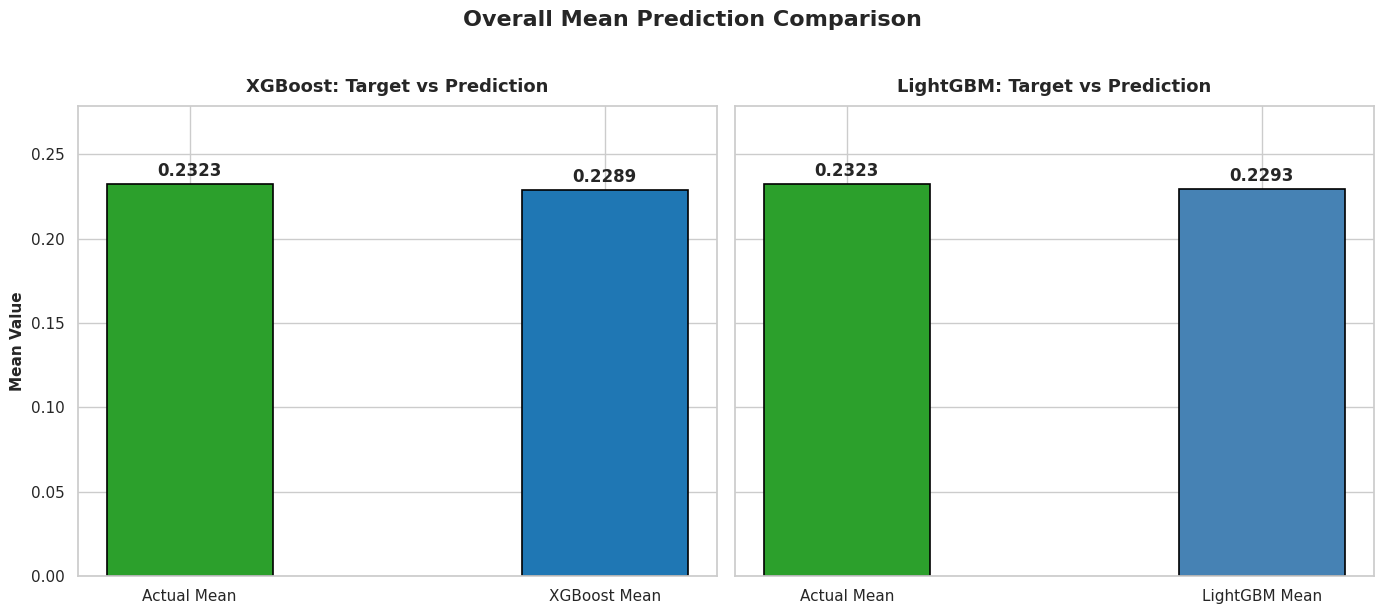

In [5]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Setup and Configurations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

actual_mean = np.mean(y_test)
plot_idx = 0

# 2. Loop and Generate exactly 2 Graphs
for model_name, file_name in models_to_plot.items():
    path = os.path.join(MODEL_DIR, file_name)

    if os.path.exists(path):
        # Load and predict
        model = joblib.load(path)
        y_pred = model.predict(X_tree_test)
        pred_mean = np.mean(y_pred)

        # Plot data setup
        categories = ['Actual Mean', f'{model_name} Mean']
        means = [actual_mean, pred_mean]
        colors = ['#2ca02c', '#1f77b4' if model_name == 'XGBoost' else '#4682B4']

        # Bar plot on current axis
        ax = axes[plot_idx]
        bars = ax.bar(categories, means, color=colors, width=0.4, edgecolor='black', linewidth=1.2)

        # Value tags on top of bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + (actual_mean * 0.01),
                    f'{height:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=12)

        ax.set_title(f'{model_name}: Target vs Prediction', fontsize=13, fontweight='bold', pad=10)
        ax.set_ylabel("Mean Value" if plot_idx == 0 else "", fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', labelsize=11, labelrotation=0)

        plot_idx += 1
    else:
        print(f"⚠️ Model file {file_name} not found.")

# Layout adjusting
plt.suptitle("Overall Mean Prediction Comparison", fontsize=16, fontweight='bold', y=1.02)
plt.ylim(0, actual_mean * 1.2)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

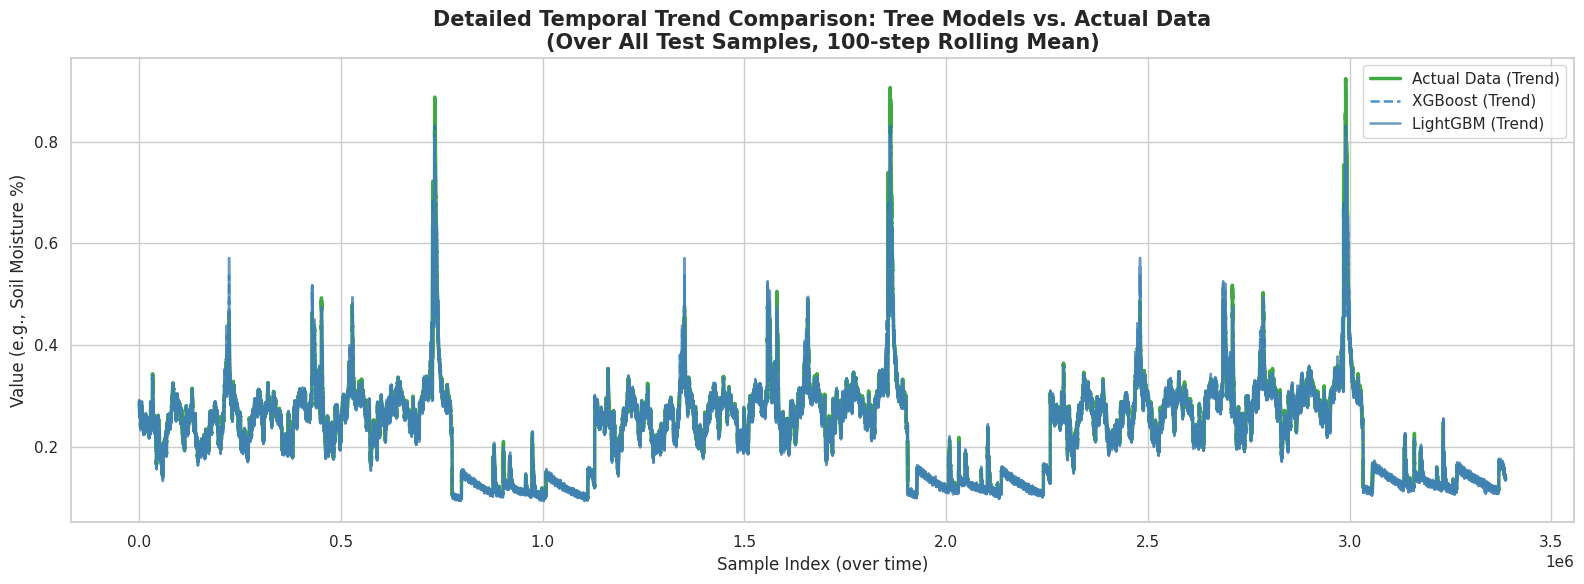

In [6]:
# (Already in memory from previous cell: y_test, X_tree_test, models_to_plot)
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

# Color palette and linestyle for tree models to overlay clearly
tree_colors = {'XGBoost': '#1f77b4', 'LightGBM': '#4682B4'}
tree_linestyle = {'XGBoost': '--', 'LightGBM': '-'}

# 1. Plot Actual test data trend (True) over the full timeline
# We use a rolling mean for smoothness, same as your example.
actual_trend = pd.Series(y_test.flatten()).rolling(window=100).mean()
plt.plot(actual_trend, label='Actual Data (Trend)', color='#2ca02c', alpha=0.9, linewidth=2.5)

# 2. Loop through tree models and plot their trends overlayed
for model_name, file_name in models_to_plot.items():
    path = os.path.join(MODEL_DIR, file_name)
    if os.path.exists(path):
        model = joblib.load(path)
        y_pred = model.predict(X_tree_test)

        # Calculate rolling mean trend for model prediction
        # Ensure it matches the flattening and alignment of actual_trend
        y_pred_f = y_pred.flatten()
        model_trend = pd.Series(y_pred_f).rolling(window=100).mean()

        # Align lengths in case of minor mismatch after rolling
        min_len = min(len(actual_trend), len(model_trend))

        # Overlay the model trend
        plt.plot(model_trend[:min_len],
                 label=f'{model_name} (Trend)',
                 color=tree_colors[model_name],
                 alpha=0.8,
                 linewidth=1.8,
                 linestyle=tree_linestyle[model_name])
    else:
        print(f"⚠️ Model {model_name} not found.")

# Formatting and Styling
plt.title("Detailed Temporal Trend Comparison: Tree Models vs. Actual Data\n(Over All Test Samples, 100-step Rolling Mean)", fontsize=15, fontweight='bold')
plt.xlabel("Sample Index (over time)", fontsize=12)
plt.ylabel("Value (e.g., Soil Moisture %)", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [8]:
from google.colab import drive
drive.mount('/content/drive')

import glob, os
import pandas as pd

# Try both spellings — the original notebook has a stray leading space
candidates = [
    '/content/drive/MyDrive/gnn_dataset_15_nodes_FINAL_V2',
    '/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2',
]
INPUT_FOLDER = next((c for c in candidates if os.path.isdir(c)), None)
if INPUT_FOLDER is None:
    raise FileNotFoundError("Neither path exists — check the exact folder name in your Drive's 'Datasets' area.")

print("Using folder:", INPUT_FOLDER)

all_files = sorted(glob.glob(os.path.join(INPUT_FOLDER, 'node_*.csv')))
print(f"Found {len(all_files)} node files")
print(all_files[:5])

# Now check date range + missing values across ALL 15 nodes, not just one
summary = []
for f in all_files:
    df = pd.read_csv(f)
    df.columns = [c.lower().strip() for c in df.columns]
    df['datetime'] = pd.to_datetime(df['datetime'])
    summary.append({
        'file': os.path.basename(f),
        'rows': len(df),
        'start': df['datetime'].min(),
        'end': df['datetime'].max(),
        'missing_pct': df.isna().mean().mean() * 100
    })

summary_df = pd.DataFrame(summary)
print(summary_df)
print("\nOverall date range:", summary_df['start'].min(), "to", summary_df['end'].max())
print("Overall span (years):", (summary_df['end'].max() - summary_df['start'].min()).days / 365.25)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using folder: /content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2
Found 15 node files
['/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2/node_0.csv', '/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2/node_1.csv', '/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2/node_10.csv', '/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2/node_11.csv', '/content/drive/MyDrive/ gnn_dataset_15_nodes_FINAL_V2/node_12.csv']
           file   rows      start                 end  missing_pct
0    node_0.csv  47112 2015-01-01 2025-11-30 23:00:00     0.019811
1    node_1.csv  47112 2015-01-01 2025-11-30 23:00:00     0.019811
2   node_10.csv  47112 2015-01-01 2025-11-30 23:00:00     0.019811
3   node_11.csv  47112 2015-01-01 2025-11-30 23:00:00     0.019811
4   node_12.csv  47112 2015-01-01 2025-11-30 23:00:00     0.019811
5   node_13.csv  47112 2015-01-01 202

In [9]:
import numpy as np
from scipy.stats import wilcoxon

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.array([
        metric_fn(y_true[idx], y_pred[idx])
        for idx in (rng.integers(0, n, n) for _ in range(n_boot))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

# Per-sequence MAE for each model, same test-set order
err_xgb   = np.abs(y_true_flat - xgb_pred_flat).mean(axis=1)
err_trans = np.abs(y_true_flat - transformer_pred_flat).mean(axis=1)

stat, p = wilcoxon(err_xgb, err_trans)
print(f"Wilcoxon signed-rank: statistic={stat:.2f}, p={p:.4g}")

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), xgb_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"XGBoost MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

NameError: name 'y_true_flat' is not defined

In [10]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SAVE_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'
X_seq_test   = np.load(f'{SAVE_DIR}/X_seq_test.npy')    # (141123, 48, 9)
y_test       = np.load(f'{SAVE_DIR}/y_test.npy')        # (141123, 24, 1)
X_seq_train  = np.load(f'{SAVE_DIR}/X_seq_train.npy')
X_phys_train = np.load(f'{SAVE_DIR}/X_phys_train.npy')
X_phys_test  = np.load(f'{SAVE_DIR}/X_phys_test.npy')
y_train      = np.load(f'{SAVE_DIR}/y_train.npy')

SOIL_IDX = 8   # soil_moisture is the last of the 9 SEQ_FEATURES
y_true_flat = y_test.reshape(len(y_test), 24)

def report(name, y_pred_flat):
    mae  = mean_absolute_error(y_true_flat, y_pred_flat)
    rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
    r2   = r2_score(y_true_flat, y_pred_flat)
    print(f"{name}: MAE={mae:.5f}  RMSE={rmse:.5f}  R2={r2:.4f}")

# Persistence: repeat the last known soil-moisture value for all 24 hours
persistence_pred = np.repeat(X_seq_test[:, -1, SOIL_IDX:SOIL_IDX+1], 24, axis=1)
report("Persistence", persistence_pred)

# Seasonal-Naive (24h): reuse hours 24-47 of the input as "yesterday's" forecast
seasonal_naive_pred = X_seq_test[:, 24:48, SOIL_IDX]
report("Seasonal-Naive (24h)", seasonal_naive_pred)

# Linear Regression: same 11-feature representation as the boosting models
X_lr_train = np.concatenate([X_seq_train[:, -1, :], X_phys_train], axis=1)
X_lr_test  = np.concatenate([X_seq_test[:, -1, :],  X_phys_test],  axis=1)
y_lr_train = y_train.reshape(len(y_train), 24)

lr = MultiOutputRegressor(LinearRegression())
lr.fit(X_lr_train, y_lr_train)
report("Linear Regression", lr.predict(X_lr_test))

Persistence: MAE=0.00949  RMSE=0.01724  R2=0.9641
Seasonal-Naive (24h): MAE=0.01162  RMSE=0.02212  R2=0.9410
Linear Regression: MAE=0.00878  RMSE=0.01660  R2=0.9668


In [11]:
import joblib
import tensorflow as tf
from tensorflow.keras import layers

MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'

# ---- 1. XGBoost predictions ----
# Saved under 'lightgbm_baseline.pkl' — this is the naming bug found earlier
# (the file actually holds the XGBoost model, not LightGBM). Loading it as-is
# is correct; only the filename is wrong.
xgb_model = joblib.load(f'{MODEL_DIR}/lightgbm_baseline.pkl')
xgb_pred_flat = xgb_model.predict(X_lr_test).reshape(-1, 24)   # X_lr_test from your baseline cell

# Sanity check against Table I (should be close to MAE .00866)
report("XGBoost (reloaded, sanity check)", xgb_pred_flat)

# ---- 2. Transformer predictions ----
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, timesteps, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pos_emb = layers.Embedding(input_dim=timesteps, output_dim=d_model)
        self.timesteps = timesteps
        self.d_model = d_model
    def call(self, x):
        positions = tf.range(start=0, limit=self.timesteps, delta=1)
        pos_enc = self.pos_emb(positions)
        return x + tf.cast(pos_enc, x.dtype)
    def get_config(self):
        config = super().get_config()
        config.update({"timesteps": self.timesteps, "d_model": self.d_model})
        return config

@tf.keras.utils.register_keras_serializable()
class TransformerEncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model//num_heads, dropout=dropout_rate)
        self.ffn = tf.keras.Sequential([layers.Dense(dff, activation='relu'), layers.Dense(d_model)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)
    def call(self, x, training=False):
        attn = self.mha(query=x, value=x, key=x, training=training)
        out1 = self.norm1(x + tf.cast(self.dropout1(attn, training=training), x.dtype))
        ffn_out = self.ffn(out1)
        return self.norm2(out1 + tf.cast(self.dropout2(ffn_out, training=training), out1.dtype))
    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model, "num_heads": self.num_heads,
                        "dff": self.dff, "dropout_rate": self.dropout_rate})
        return config

transformer_model = tf.keras.models.load_model(
    f'{MODEL_DIR}/transformer_model.h5',
    custom_objects={"PositionalEmbedding": PositionalEmbedding,
                     "TransformerEncoderBlock": TransformerEncoderBlock},
    compile=False
)
transformer_pred_flat = transformer_model.predict(X_seq_test).reshape(-1, 24)

# Sanity check against Table I (should be close to MAE .0109)
report("Transformer (reloaded, sanity check)", transformer_pred_flat)

# ---- 3. Now the significance test / CI code will actually run ----
err_xgb   = np.abs(y_true_flat - xgb_pred_flat).mean(axis=1)
err_trans = np.abs(y_true_flat - transformer_pred_flat).mean(axis=1)

stat, p = wilcoxon(err_xgb, err_trans)
print(f"Wilcoxon signed-rank: statistic={stat:.2f}, p={p:.4g}")

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), xgb_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"XGBoost MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

mean_mae_t, std_mae_t, ci_t = bootstrap_ci(
    y_true_flat.flatten(), transformer_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"Transformer MAE: {mean_mae_t:.5f} +/- {std_mae_t:.5f}, 95% CI {ci_t}")

XGBoost (reloaded, sanity check): MAE=0.00866  RMSE=0.01440  R2=0.9750


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/drive/MyDrive/Datasets/comparison_models/transformer_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [12]:
mean_mae, std_mae, ci = bootstrap_ci(y_true_flat.flatten(), pred_flat.flatten(),
                                       lambda a, b: np.mean(np.abs(a - b)))
print(f"MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

NameError: name 'pred_flat' is not defined

In [13]:
def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.array([
        metric_fn(y_true[idx], y_pred[idx])
        for idx in (rng.integers(0, n, n) for _ in range(n_boot))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), xgb_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"XGBoost MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

XGBoost MAE: 0.00866 +/- 0.00001, 95% CI [0.0086462 0.0086707]


In [14]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SAVE_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'
X_seq_test   = np.load(f'{SAVE_DIR}/X_seq_test.npy')    # (141123, 48, 9)
y_test       = np.load(f'{SAVE_DIR}/y_test.npy')        # (141123, 24, 1)
X_seq_train  = np.load(f'{SAVE_DIR}/X_seq_train.npy')
X_phys_train = np.load(f'{SAVE_DIR}/X_phys_train.npy')
X_phys_test  = np.load(f'{SAVE_DIR}/X_phys_test.npy')
y_train      = np.load(f'{SAVE_DIR}/y_train.npy')

SOIL_IDX = 8   # soil_moisture is the last of the 9 SEQ_FEATURES
y_true_flat = y_test.reshape(len(y_test), 24)

def report(name, y_pred_flat):
    mae  = mean_absolute_error(y_true_flat, y_pred_flat)
    rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
    r2   = r2_score(y_true_flat, y_pred_flat)
    print(f"{name}: MAE={mae:.5f}  RMSE={rmse:.5f}  R2={r2:.4f}")

# Persistence: repeat the last known soil-moisture value for all 24 hours
persistence_pred = np.repeat(X_seq_test[:, -1, SOIL_IDX:SOIL_IDX+1], 24, axis=1)
report("Persistence", persistence_pred)

# Seasonal-Naive (24h): reuse hours 24-47 of the input as "yesterday's" forecast
seasonal_naive_pred = X_seq_test[:, 24:48, SOIL_IDX]
report("Seasonal-Naive (24h)", seasonal_naive_pred)

# Linear Regression: same 11-feature representation as the boosting models
X_lr_train = np.concatenate([X_seq_train[:, -1, :], X_phys_train], axis=1)
X_lr_test  = np.concatenate([X_seq_test[:, -1, :],  X_phys_test],  axis=1)
y_lr_train = y_train.reshape(len(y_train), 24)

lr = MultiOutputRegressor(LinearRegression())
lr.fit(X_lr_train, y_lr_train)
report("Linear Regression", lr.predict(X_lr_test))

Persistence: MAE=0.00949  RMSE=0.01724  R2=0.9641
Seasonal-Naive (24h): MAE=0.01162  RMSE=0.02212  R2=0.9410
Linear Regression: MAE=0.00878  RMSE=0.01660  R2=0.9668
